# MODULE 45 — FACE DETECTION, LANDMARKS & ALIGNMENT

## 45.4 Face Preprocessing

**Priority:** Must Know  
**Domain:** Computer Vision

Face preprocessing is the process of preparing a detected and aligned face image before passing it into a deep learning model.

Think of it this way:

A face recognition model expects input images in a particular format. Real-world camera images, however, may have different dimensions, brightness levels, colour distributions and face positions.

Preprocessing helps convert these images into a consistent format.

The four topics in this syllabus are:

1. Cropping
2. Resizing
3. Normalization
4. Illumination handling

---

## 1. Cropping

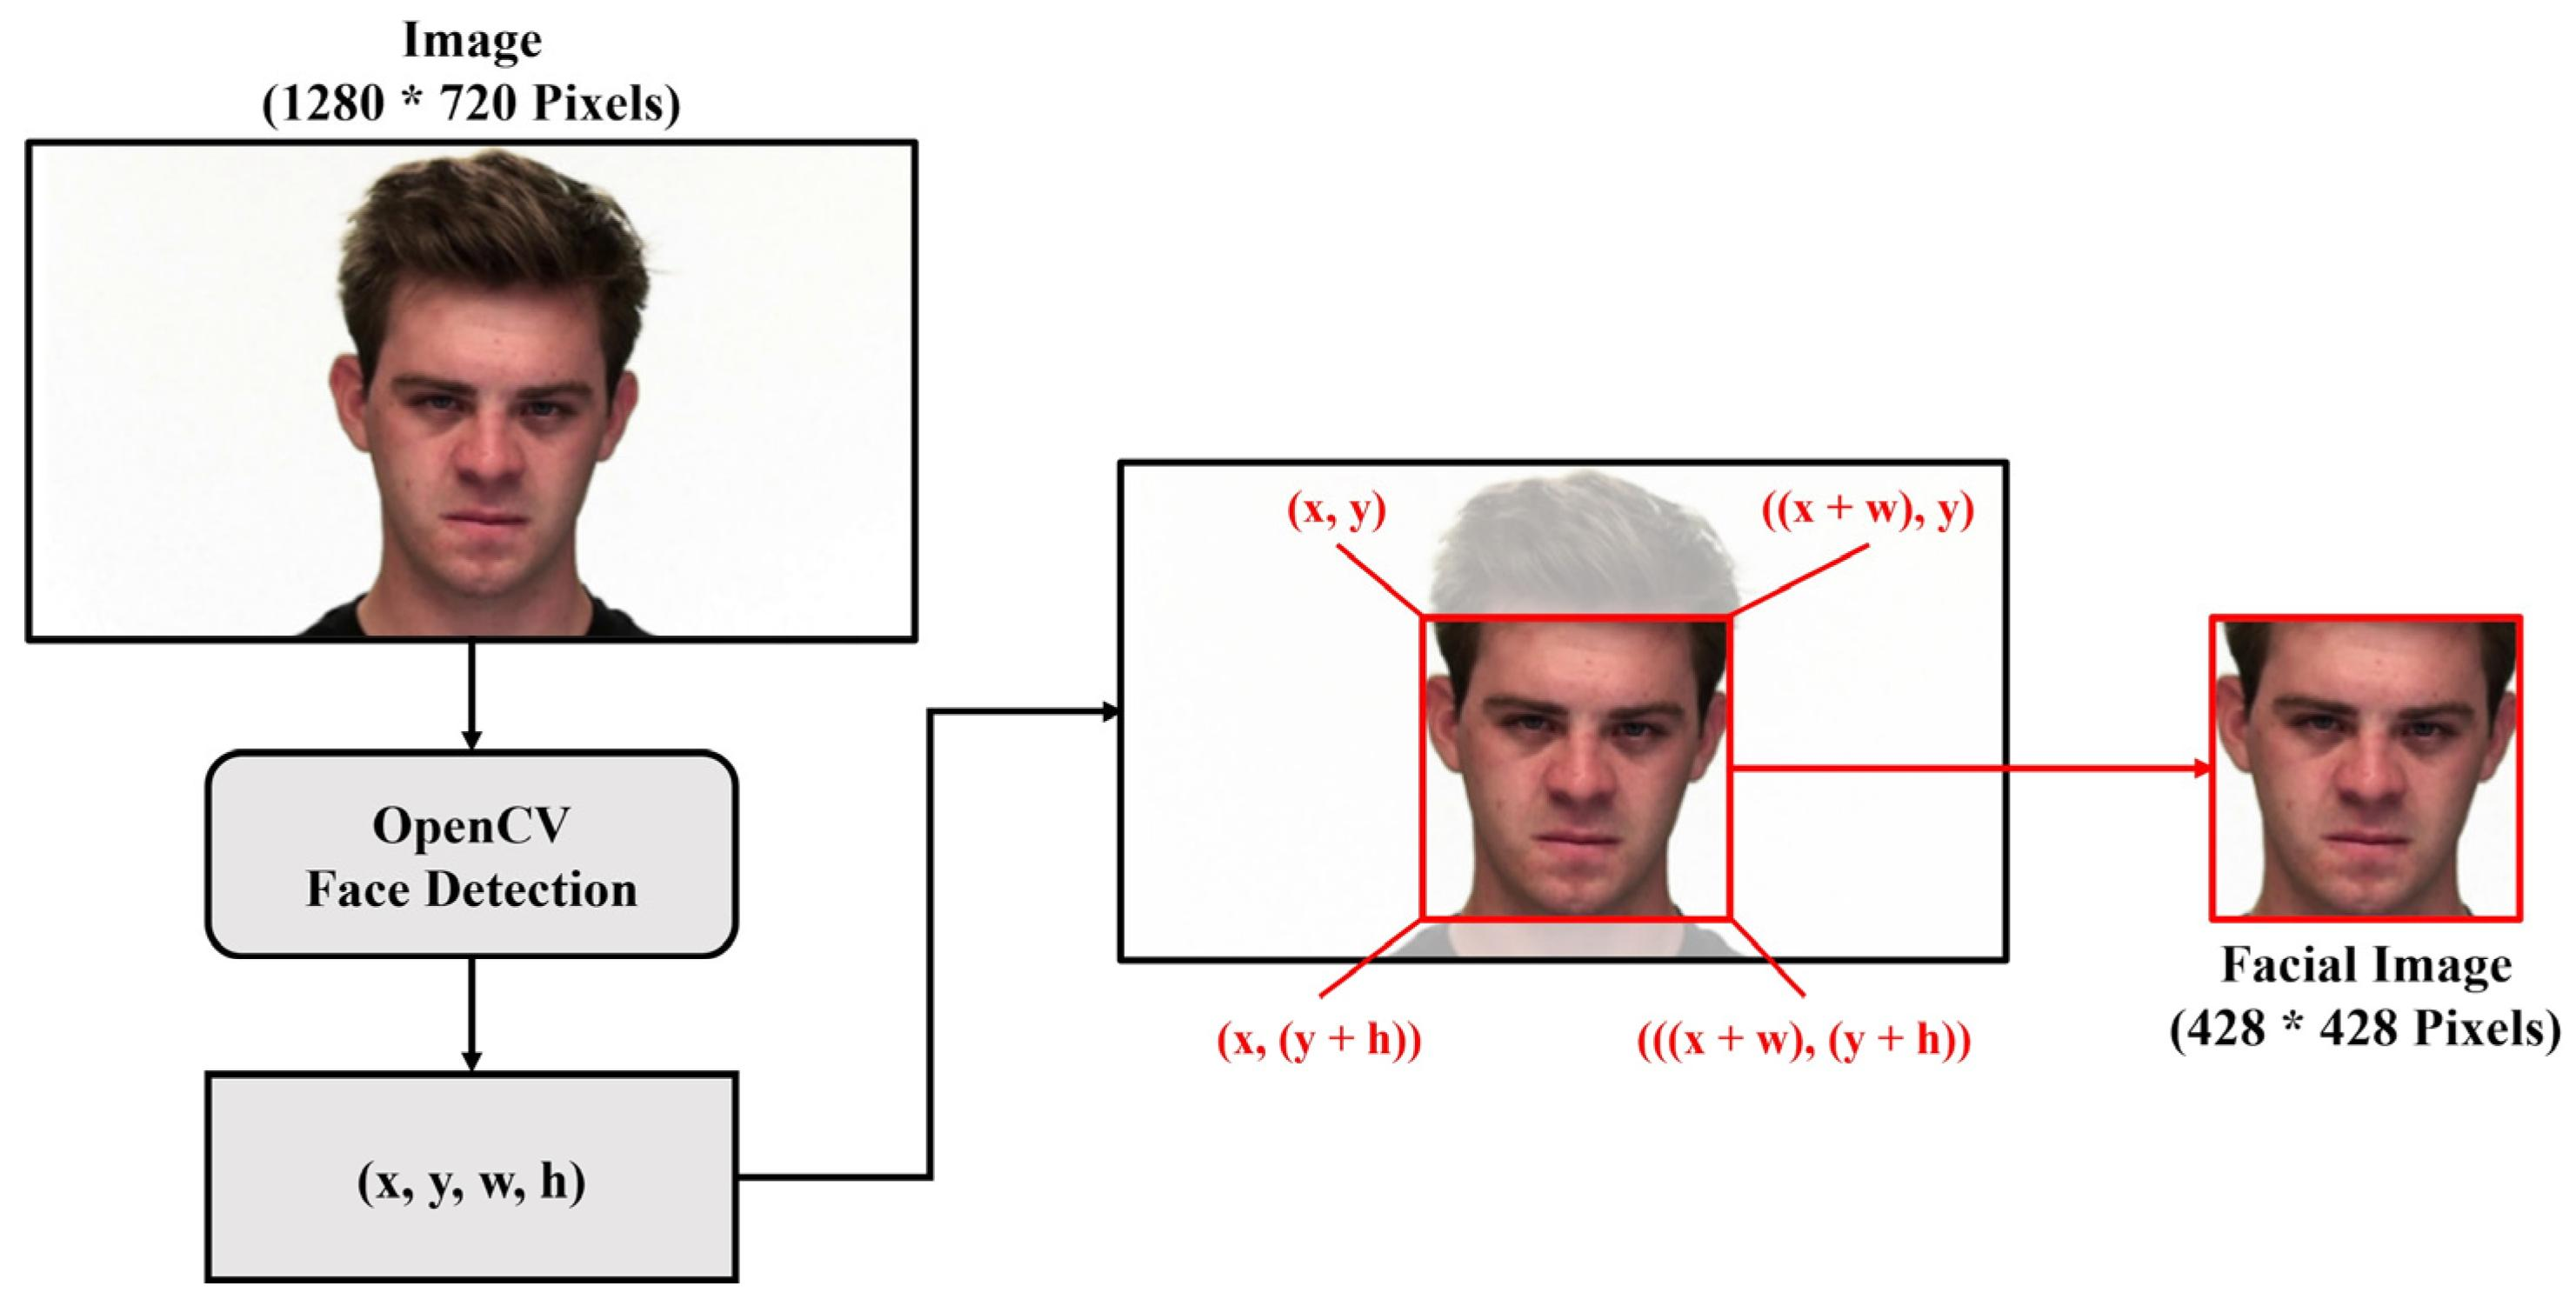

Cropping means extracting the required face region from the original image.

Suppose a camera captures an image containing a person's entire body and background.

The face detector returns:

```python
x1, y1, x2, y2 = 100, 50, 300, 250
```

These coordinates represent the bounding box:

- `x1, y1`: Top-left corner.
- `x2, y2`: Bottom-right corner.

We extract only that region.

### OpenCV implementation

```python
import cv2

image = cv2.imread("person.jpg")

x1, y1, x2, y2 = 100, 50, 300, 250

face_crop = image[y1:y2, x1:x2]

cv2.imshow("Cropped Face", face_crop)
cv2.waitKey(0)
cv2.destroyAllWindows()
```

Notice the indexing:

```python
image[y1:y2, x1:x2]
```

OpenCV images are accessed using:

```python
image[row, column]
image[y, x]
```

### Why cropping matters

- Removes irrelevant background information.
- Focuses the model on facial features.
- Reduces unnecessary image data.
- Prepares the face region for subsequent processing.

**Important:** In a practical pipeline, ensure bounding-box coordinates are inside image boundaries. Also, a small margin around the face may be useful to avoid cutting off facial features.

---

## 2. Resizing

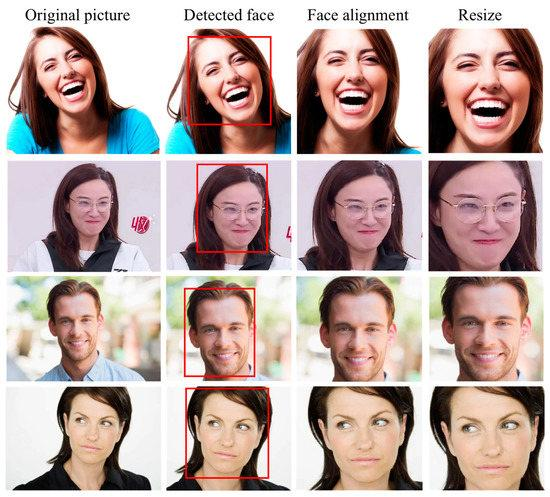

Different cameras and detection models produce face crops with different dimensions.

For example:

| Input face | Dimensions |
|---|---:|
| Camera A | 300 × 300 |
| Camera B | 180 × 180 |
| Camera C | 500 × 500 |

But a deep learning model generally expects a fixed input size.

For example:

```text
Face crop
    ↓
Resize
    ↓
112 × 112 × 3
    ↓
Recognition model
```

The dimensions 112 × 112 are commonly used by some face recognition architectures, although the required size depends on the model.

### OpenCV implementation

```python
resized_face = cv2.resize(
    face_crop,
    (112, 112)
)
```

### What happens during resizing?

The original pixel grid is mapped onto a new pixel grid using interpolation.

Common interpolation methods:

| Method | Usage |
|---|---|
| `INTER_NEAREST` | Nearest-neighbour interpolation |
| `INTER_LINEAR` | Bilinear interpolation |
| `INTER_CUBIC` | Bicubic interpolation |
| `INTER_AREA` | Often useful for shrinking images |

For example:

```python
resized_face = cv2.resize(
    face_crop,
    (112, 112),
    interpolation=cv2.INTER_AREA
)
```

**Important:** Resizing does not simply change the displayed dimensions. It calculates new pixel values. Excessive resizing can remove important facial details.

Also, resizing directly to a square can distort the face if the original crop is not square. A proper face-alignment pipeline typically handles geometry before producing the model's expected dimensions.

---

## 3. Normalization

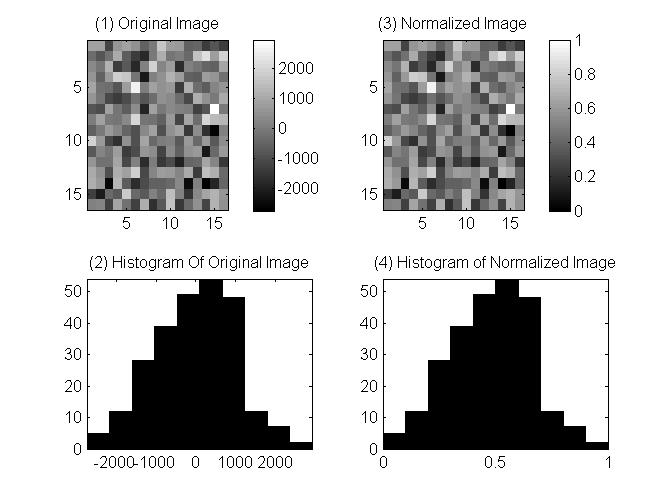

Normalization means converting image pixel values into a suitable numerical range before feeding them into a neural network.

Remember: a colour image generally contains three channels:

- Red (R)
- Green (G)
- Blue (B)

Each channel typically contains pixel values between 0 and 255 when stored as an 8-bit image.

For example:

**Original pixel values:**

```text
R = 200
G = 100
B = 50
```

Many deep learning pipelines convert these values into floating-point numbers and normalize them.

### A. Min-max normalization

A common approach is scaling pixel values from `[0, 255]` to `[0, 1]`.

**Formula:**

$$
X_{\text{normalized}}=\frac{X}{255}
$$

**Example:**

$$
\frac{200}{255}=0.784
$$

$$
\frac{100}{255}=0.392
$$

$$
\frac{50}{255}=0.196
$$

So the normalized pixel becomes:

```python
[0.784, 0.392, 0.196]
```

### B. Mean-std normalization

Another common approach is standardization:

**Formula:**

$$
X_{\text{normalized}}=\frac{X-\mu}{\sigma}
$$

Where:

- \(X\) = Original pixel value (after any required scaling).
- \(\mu\) = Mean of the channel or dataset.
- \(\sigma\) = Standard deviation.

For example, if:

$$
X=0.8,\quad \mu=0.5,\quad \sigma=0.25
$$

Then:

$$
X_{\text{normalized}}=\frac{0.8-0.5}{0.25}=1.2
$$

This transforms the input distribution into a scale centred around zero, using the chosen mean and standard deviation.

**Important:** The mean and standard deviation must match the preprocessing expected by the pretrained model. Do not arbitrarily choose normalization values.

### PyTorch implementation

```python
import torchvision.transforms as transforms

preprocess = transforms.Compose([
    transforms.Resize((112, 112)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])
```

Here:

- `ToTensor()` converts image data into a tensor and scales typical 8-bit pixel values to `[0, 1]`.
- `Normalize()` applies channel-wise mean and standard deviation normalization.

With mean and standard deviation both set to 0.5, the resulting values are approximately in `[-1, 1]`.

---

## 4. Illumination Handling

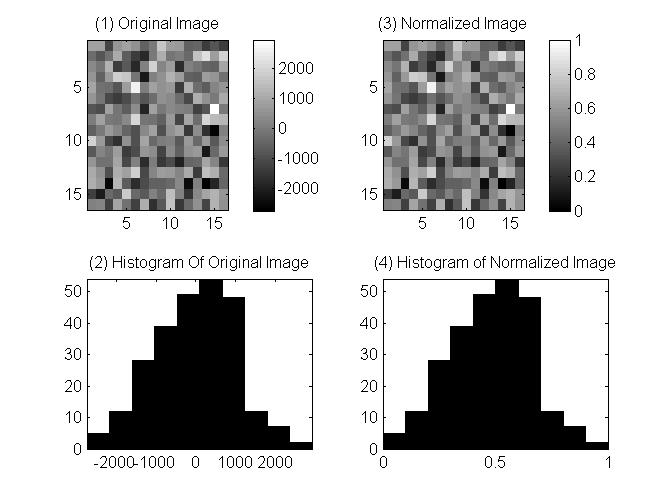

Illumination refers to the lighting conditions under which a face image is captured.

In real-world environments, the same person's face can appear very different depending on lighting.

Examples:

- Bright sunlight.
- Dim indoor lighting.
- Shadows across the face.
- Backlighting.
- Uneven lighting on the left and right sides.

### Why is illumination handling necessary?

Imagine a face recognition system installed at an office entrance.

During the morning, sunlight illuminates the person's face.

During the evening, the same person enters under dim lighting.

The identity has not changed, but the pixel intensities and visible facial details have changed.

Illumination handling attempts to reduce these unwanted lighting variations.

### A. Histogram Equalization

Histogram equalization redistributes image intensity values to improve contrast.

It is particularly useful when an image has a narrow intensity distribution.

**OpenCV example:**

```python
import cv2

image = cv2.imread("face.jpg")

gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

equalized = cv2.equalizeHist(gray)

cv2.imshow("Original", gray)
cv2.imshow("Equalized", equalized)

cv2.waitKey(0)
cv2.destroyAllWindows()
```

**Limitation:** Basic histogram equalization operates on a single-channel grayscale image. It can also amplify noise or make the image look unnatural.

### B. CLAHE

CLAHE stands for **Contrast Limited Adaptive Histogram Equalization**.

Unlike global histogram equalization, CLAHE improves contrast in local image regions.

It also limits contrast amplification to reduce excessive enhancement.

**OpenCV implementation:**

```python
import cv2

image = cv2.imread("face.jpg")

gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

cv2.imshow("Original", gray)
cv2.imshow("CLAHE", enhanced)

cv2.waitKey(0)
cv2.destroyAllWindows()
```

**Understanding the parameters:**

- `clipLimit`: Controls contrast amplification.
- `tileGridSize`: Controls the local regions used for enhancement.

### C. Gamma Correction

Gamma correction adjusts image brightness using a nonlinear transformation.

**Formula:**

$$
I_{\text{output}}=I_{\text{input}}^\gamma
$$

Here, input intensity is first scaled to `[0, 1]`.

- \(\gamma<1\): Brightens the image.
- \(\gamma>1\): Darkens the image.
- \(\gamma=1\): No change.

**Example:**

```python
import cv2
import numpy as np

image = cv2.imread("face.jpg")

gamma = 0.7

lookup_table = np.array([
    ((i / 255.0) ** gamma) * 255
    for i in range(256)
]).astype("uint8")

corrected = cv2.LUT(image, lookup_table)

cv2.imshow("Gamma Corrected", corrected)

cv2.waitKey(0)
cv2.destroyAllWindows()
```

Gamma correction is useful for certain brightness problems, but it cannot recover facial information that was never captured because of severe underexposure or saturation.

---

## 5. Complete Face Preprocessing Pipeline

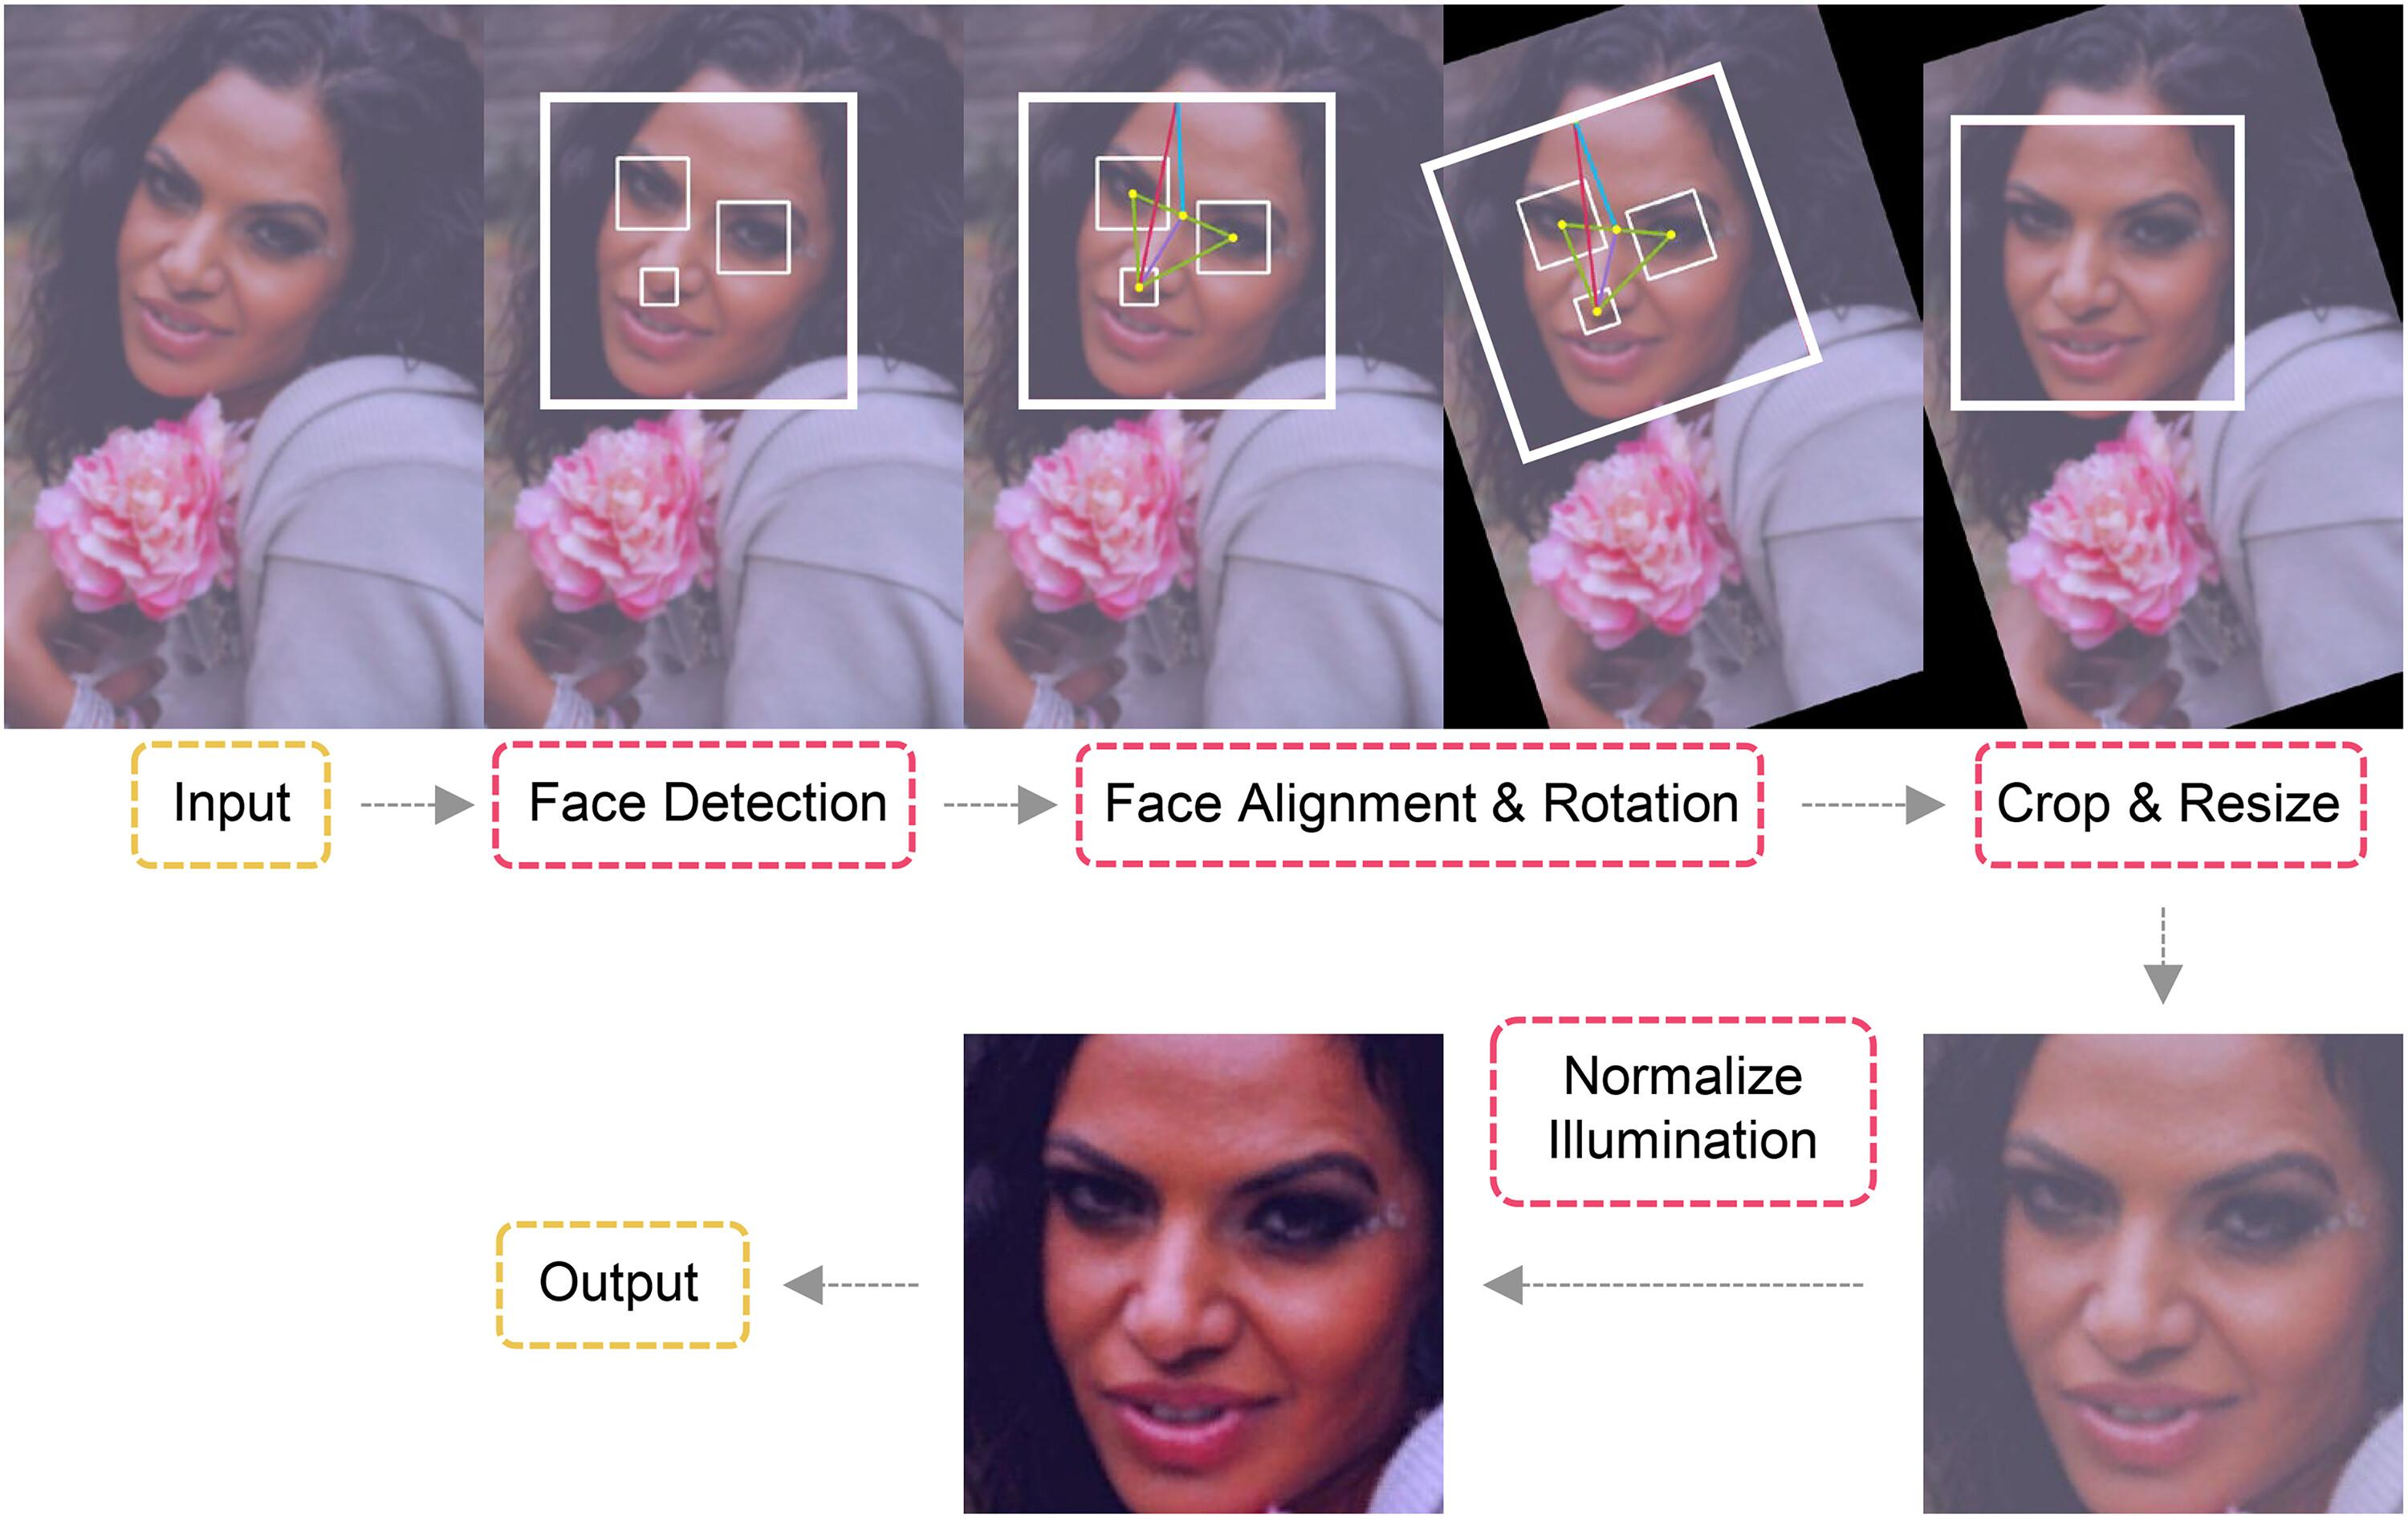

Now let's connect all four concepts.

**Pipeline:**

```text
Original Image
      |
      v
Face Detection
      |
      v
Face Cropping
      |
      v
Face Alignment
      |
      v
Resizing (112 × 112)
      |
      v
Illumination Handling
      |
      v
Normalization
      |
      v
Face Recognition Model
      |
      v
Face Embedding
```

The exact order can vary depending on the model and preprocessing pipeline. For example, illumination enhancement may be applied before alignment, and some recognition models do not require explicit illumination correction.

---

## 6. Comparison of Preprocessing Techniques

| Technique | Main purpose |
|---|---|
| Cropping | Extract the face region |
| Resizing | Standardize image dimensions |
| Normalization | Prepare pixel values for the model |
| Histogram equalization | Improve global contrast |
| CLAHE | Improve local contrast |
| Gamma correction | Adjust brightness |

---

## 7. Industry Perspective

Consider a face authentication system.

| Real-world problem | Preprocessing solution |
|---|---|
| Large background area | Cropping |
| Different camera resolutions | Resizing |
| Inconsistent pixel ranges | Normalization |
| Dimly lit environment | Illumination handling |
| Face at an angle | Face alignment |

One important engineering point: **preprocessing must be consistent between training and inference.** If you train a model using one normalization method and deploy it using another, recognition performance can deteriorate.

---

## 8. What You Should Remember

1. Cropping extracts the detected face from the original image.
2. Resizing converts the face into the required model input dimensions.
3. Normalization transforms pixel values into an appropriate numerical range.
4. Histogram equalization improves global contrast.
5. CLAHE improves local contrast while limiting excessive enhancement.
6. Gamma correction adjusts image brightness.
7. Preprocessing should match the recognition model's expected input pipeline.

---

## 9. Knowledge Priority

| Topic | Priority |
|---|---|
| Cropping and bounding-box indexing | Must Know |
| Resizing and interpolation | Must Know |
| Min-max normalization | Must Know |
| Mean-std normalization | Must Know |
| Histogram equalization | Good to Know |
| CLAHE | Good to Know |
| Gamma correction | Good to Know |

---
